# 04 - Comparison of the three models
Run notebooks 01-03 first. This notebook reloads the saved models, re-scores them on the test set and compares them.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import torch
from torch import nn
from torchvision import datasets
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR, ART_DIR, CHARTS_DIR = ROOT / "app" / "models", ROOT / "artifacts", ROOT / "app" / "charts"

test = datasets.MNIST(str(ROOT / "data"), train=False, download=True)
x_test, y_test = test.data.numpy().astype(np.float32) / 255, test.targets.numpy()

## Load the saved models and predict on the test set

In [2]:
class MLP(nn.Module):
    def __init__(self, hidden_sizes=(256, 128), dropout=0.2):
        super().__init__()
        layers, n_in = [], 28 * 28
        for h in hidden_sizes:
            layers += [nn.Linear(n_in, h), nn.ReLU(), nn.Dropout(dropout)]
            n_in = h
        layers.append(nn.Linear(n_in, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class SimpleCNN(nn.Module):
    def __init__(self, filters=(16, 32), fc_units=64, dropout=0.3):
        super().__init__()
        f1, f2 = filters
        self.features = nn.Sequential(
            nn.Conv2d(1, f1, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(f1, f2, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(f2 * 7 * 7, fc_units), nn.ReLU(), nn.Dropout(dropout), nn.Linear(fc_units, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def load_torch(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    model = {"mlp": MLP, "cnn": SimpleCNN}[ckpt["arch"]](**ckpt["config"])
    model.load_state_dict(ckpt["state_dict"])
    return model.eval()


@torch.no_grad()
def predict_torch(model, x):
    return torch.cat([model(torch.from_numpy(x[i:i + 2048])).argmax(1) for i in range(0, len(x), 2048)]).numpy()


flat = x_test.reshape(len(x_test), -1)
preds = {
    "SVM": joblib.load(MODELS_DIR / "classical_svm.joblib").predict(flat),
    "MLP": predict_torch(load_torch(MODELS_DIR / "mlp_model.pt"), flat),
    "CNN": predict_torch(load_torch(MODELS_DIR / "cnn_model.pt"), x_test[:, None]),
}
results = {n: json.loads((ART_DIR / f"{n.lower()}_results.json").read_text()) for n in preds}
for n, p in preds.items():
    print(n, "test accuracy:", accuracy_score(y_test, p), "(training notebook:", results[n]["test_acc"], ")")

SVM test accuracy: 0.9851 (training notebook: 0.9851 )
MLP test accuracy: 0.9824 (training notebook: 0.9824 )
CNN test accuracy: 0.9895 (training notebook: 0.9895 )


## Comparison table

In [3]:
table = pd.DataFrame({n: {
    "train acc": r["train_acc"], "val acc": r["val_acc"], "test acc": r["test_acc"],
    "gap (train - test)": r["train_acc"] - r["test_acc"], "macro F1": r["macro_f1"],
    "test errors": r["test_errors"], "train time (s)": r["train_time_s"],
    "inference (ms/img)": r["inference_ms_per_img"], "parameters": r["parameters"], "file size (MB)": r["file_size_mb"],
} for n, r in results.items()}).T
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
table.to_csv(CHARTS_DIR / "model_comparison.csv")   # the web app shows this table
table.style.format({"train acc": "{:.4f}", "val acc": "{:.4f}", "test acc": "{:.4f}", "gap (train - test)": "{:.4f}",
                    "macro F1": "{:.4f}", "train time (s)": "{:.1f}", "inference (ms/img)": "{:.3f}",
                    "parameters": "{:,.0f}", "file size (MB)": "{:.2f}", "test errors": "{:.0f}"})

,train acc,val acc,test acc,gap (train - test),macro F1,test errors,train time (s),inference (ms/img),parameters,file size (MB)
SVM,0.9999,0.9842,0.9851,0.0148,0.9850,149,200.9,4.232,"9,763,152",5.83
MLP,0.9972,0.9815,0.9824,0.0148,0.9823,176,7.1,0.001,"235,146",0.94
CNN,0.9969,0.9887,0.9895,0.0074,0.9894,105,84.5,0.053,"105,866",0.43


## Charts

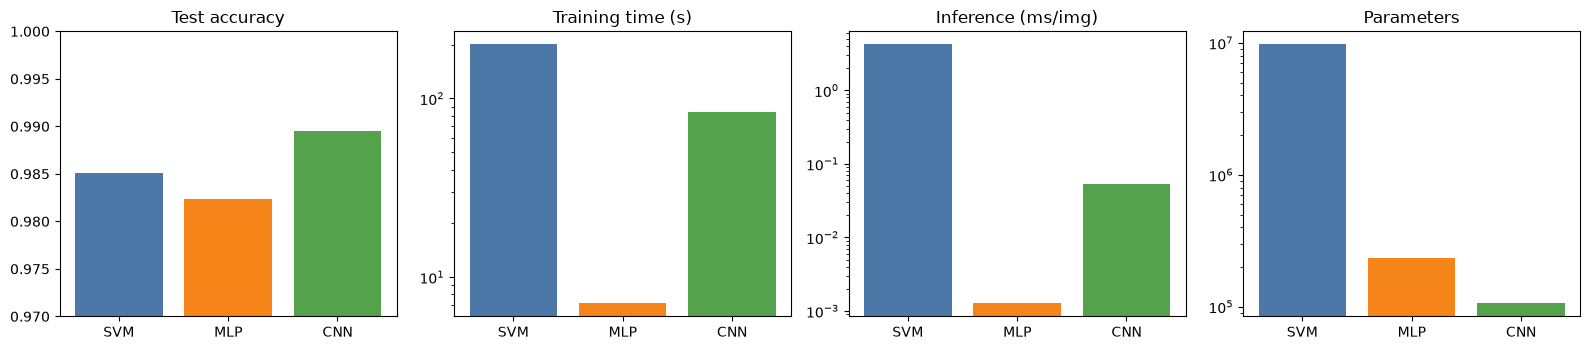

In [4]:
colors = ["#4c78a8", "#f58518", "#54a24b"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (col, title, log) in zip(ax, [("test acc", "Test accuracy", False), ("train time (s)", "Training time (s)", True),
                                     ("inference (ms/img)", "Inference (ms/img)", True), ("parameters", "Parameters", True)]):
    a.bar(table.index, table[col], color=colors)
    a.set_title(title)
    if log:
        a.set_yscale("log")
    if col == "test acc":
        a.set_ylim(0.97, 1.0)
plt.tight_layout()
CHARTS_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(CHARTS_DIR / "comparison.png", dpi=120)
plt.show()

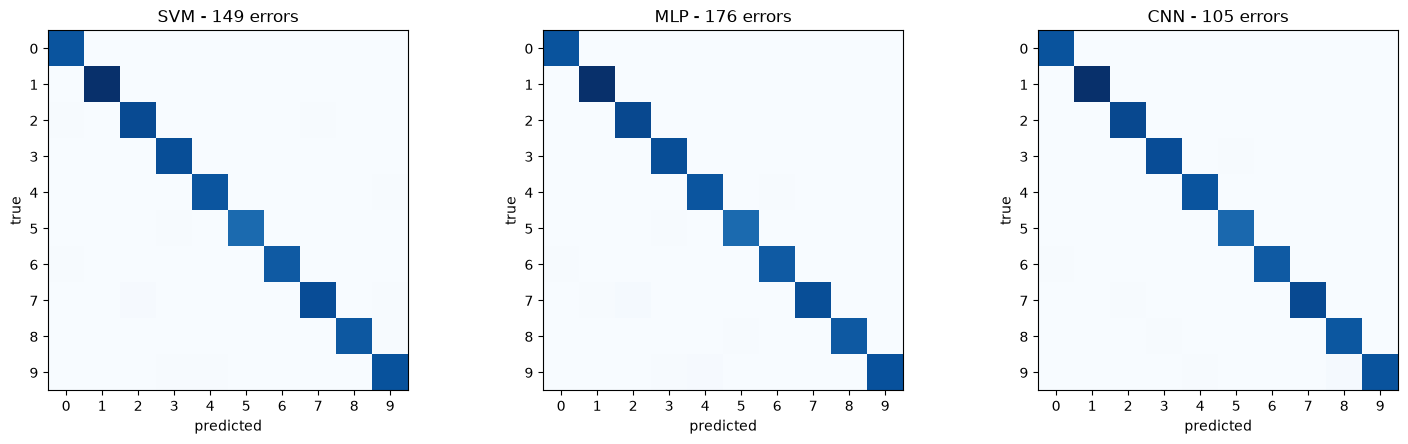

,0,1,2,3,4,5,6,7,8,9
SVM,0.989,0.993,0.983,0.987,0.987,0.985,0.989,0.980,0.984,0.975
MLP,0.988,0.990,0.982,0.981,0.983,0.980,0.986,0.976,0.978,0.979
CNN,0.992,0.995,0.991,0.991,0.992,0.990,0.993,0.989,0.982,0.979


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, (n, p) in zip(ax, preds.items()):
    a.imshow(confusion_matrix(y_test, p), cmap="Blues")
    a.set_title(f"{n} - {(p != y_test).sum()} errors")
    a.set_xlabel("predicted"); a.set_ylabel("true")
    a.set_xticks(range(10)); a.set_yticks(range(10))
plt.tight_layout()
plt.show()

# digits each model finds hardest (lowest per-class F1)
pd.DataFrame({n: f1_score(y_test, p, average=None) for n, p in preds.items()}).round(3).T

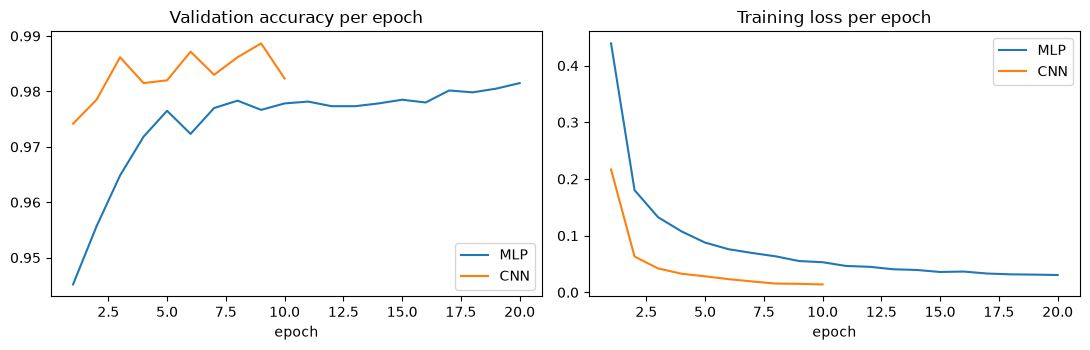

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for n in ("MLP", "CNN"):
    h = results[n]["history"]
    ax[0].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=n)
    ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label=n)
ax[0].set_title("Validation accuracy per epoch"); ax[1].set_title("Training loss per epoch")
for a in ax:
    a.set_xlabel("epoch"); a.legend()
plt.tight_layout()
plt.show()

## Choosing the best model
The winner on each criterion:

In [7]:
pd.Series({
    "performance (highest test acc)": table["test acc"].idxmax(),
    "generalisation (smallest train-test gap)": table["gap (train - test)"].idxmin(),
    "training time (fastest)": table["train time (s)"].idxmin(),
    "complexity (fewest parameters)": table["parameters"].idxmin(),
    "inference speed (fastest)": table["inference (ms/img)"].idxmin(),
})

performance (highest test acc)              CNN
generalisation (smallest train-test gap)    CNN
training time (fastest)                     MLP
complexity (fewest parameters)              CNN
inference speed (fastest)                   MLP
dtype: str